In [1]:
import DataGen as dtg
import torch
import torch.nn as nn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from tqdm.auto import tqdm
from efficient_kan.kan import KAN
from torch.utils.data import TensorDataset, DataLoader, Sampler

import torch.optim as optim
from architecture import Architecture
from metrics import score
SEED = 42

c:\Users\2052180\AppData\Local\miniconda3\envs\pikan\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using '{DEVICE}' device.")

Using 'cpu' device.


## Obtenção do conjunto de dados

### Definindo o espaço de velocidade


In [3]:
X_POINTS = 30
Z_POINTS = 30
Y_POINTS = 1

X_DISTANCE = 1
Y_DISTANCE = 1
Z_DISTANCE = 1


In [10]:
dg_over = 1
xover = np.arange(0, 29 + dg_over, dg_over)
zover = np.arange(0, 29 + dg_over, dg_over)

v_line_z = 1.5 + zover
v_line_x = np.tile(0.3 * xover, (len(zover), 1))
v_depth = np.tile(v_line_z[:, np.newaxis], (1, len(xover))) + v_line_x

v_depth = v_depth.reshape(X_POINTS,Z_POINTS,Y_POINTS) # necessário adicionar a terceira dimensão para o modelo do Solver

In [5]:
# dg_over = 0.1
# xover = np.arange(0, 3, dg_over)
# zover = np.arange(0, 3, dg_over)

# v_line_z = 1.5 + zover
# v_line_x = np.tile(0.3 * xover, (len(zover), 1))
# v_depth = np.tile(v_line_z[:, np.newaxis], (1, len(xover))) + v_line_x

# v_depth = v_depth.reshape(X_POINTS,Z_POINTS,Y_POINTS) # necessário adicionar a terceira dimensão para o modelo do Solver

In [11]:
df = dtg.generateMultipleData(
    nPoints = (X_POINTS, Z_POINTS, Y_POINTS), 
    nodeDistances = (X_DISTANCE, Y_DISTANCE, Z_DISTANCE),
    velocityModel = v_depth,
    sourceOriginInterval= [[0,0],[1,2]])

In [7]:
new_df = dtg.check_derivatives(df)
new_df


c:\Users\2052180\Documents\testes_vini\DataGen.py:64: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  new_data['dt_dx'].replace([np.inf, -np.inf], 0, inplace=True)
c:\Users\2052180\Documents\testes_vini\DataGen.py:65: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when do

,x,z,travel_time,source_x0,source_z0,dt_dx,dt_dz,velocity_hat,velocity
0,0,0,0.000000,0,0,NaN,NaN,NaN,1.5
1,0,1,0.555556,0,0,0.000000,0.555556,1.800000,1.8
2,0,2,1.057952,0,0,0.000000,0.528976,1.890444,2.1
3,0,3,1.471818,0,0,0.000000,0.490606,2.038295,2.4
4,0,4,1.798654,0,0,0.000000,0.449664,2.223885,2.7
...,...,...,...,...,...,...,...,...,...
895,29,25,2.543183,1,2,0.090828,0.110573,6.988370,38.0
896,29,26,2.565888,1,2,0.091639,0.106912,7.101697,38.3
897,29,27,2.588907,1,2,0.092461,0.103556,7.203211,38.6
898,29,28,2.612187,1,2,0.093292,0.100469,7.293748,38.9


In [15]:
from sklearn.linear_model import LinearRegression

def ajustar_funcao_velocidade(data: pd.DataFrame):
    # Variáveis independentes
    X = data[['x', 'z']]  # colunas de entrada
    y = data['velocidade_media']  # saída

    # Cria e treina o modelo
    modelo = LinearRegression()
    modelo.fit(X, y)

    # Coeficientes
    a, b = modelo.coef_
    c = modelo.intercept_

    print(f"Função ajustada: v(x, z) = {a:.4f} * x + {b:.4f} * z + {c:.4f}")
    return modelo

In [16]:
ajustar_funcao_velocidade(new_df)

Função ajustada: v(x, z) = 0.2481 * x + 0.1352 * z + 3.0778


LinearRegression()

In [12]:
features = ['x', 'z', 'source_x0', 'source_z0']
target = ['travel_time']

### Separando o conjunto em Treinamento, Validação e Teste

In [13]:
initial_conditions = df[['source_x0', 'source_z0']].drop_duplicates().reset_index(drop=True)
aux = initial_conditions.copy()

ic_train = aux.sample(frac=0.6, random_state=SEED)
ic_val = aux.drop(ic_train.index).sample(frac=0.5, random_state=SEED)
ic_test = aux.drop(list(ic_train.index) + list(ic_val.index))

print("Train Initial Conditions:", len(ic_train))
print("Validation Initial Conditions:", len(ic_val))
print("Test Initial Conditions:", len(ic_test))

Train Initial Conditions: 4
Validation Initial Conditions: 1
Test Initial Conditions: 1


In [14]:
df_train = df.merge(ic_train, on=['source_x0', 'source_z0'], how='inner')
df_val = df.merge(ic_val, on=['source_x0', 'source_z0'], how='inner')
df_test = df.merge(ic_test, on=['source_x0', 'source_z0'], how='inner')

print("Train Size:", len(df_train))
print("Validation Size:", len(df_val))
print("Test Size:", len(df_test))

Train Size: 3600
Validation Size: 900
Test Size: 900


In [15]:
from itertools import cycle
import random


class BalancedBatchSampler(Sampler):
    def __init__(self, dataset, batch_size, t_index=3, shuffle=True):
        """
    A sampler that generates balanced batches from a dataset, ensuring that each batch contains
    an equal number of samples with a specific target value.
    Args:
        dataset (Dataset): The dataset to sample from.
        batch_size (int): The number of samples per batch.
        t_index (int, optional): The index of the target value in the dataset samples. Default is 4.
        shuffle (bool, optional): Whether to shuffle the batch indices. Default is True.
        
    Attributes:
        dataset (Dataset): The dataset to sample from.
        batch_size (int): The number of samples per batch.
        t_index (int): The index of the target value in the dataset samples.
        shuffle (bool): Whether to shuffle the batch indices.
        t_zero_indices (list): Indices of samples with target value equal to 0.
        non_t_zero_indices (list): Indices of samples with target value not equal to 0.
        
    Methods:
        __iter__(): Generates balanced batches of indices.
        __len__(): Returns the number of batches.
    """
        if batch_size % 2 != 0 or batch_size <= 0:
            raise ValueError("batch_size deve ser um número inteiro positivo e par.")
        
        self.dataset = dataset
        self.batch_size = batch_size
        self.t_index = t_index
        self.shuffle = shuffle

        # Dividir o dataset em duas partes: com t=0 e sem t=0
        self.t_zero_indices = []
        self.non_t_zero_indices = []

        for i in range(len(self.dataset)):
            data = self.dataset[i]
            try:
                t_sample = data[0][self.t_index]
            except (IndexError, TypeError):
                raise ValueError(f"O índice de tempo t_index={self.t_index} não é válido.")
            if t_sample == 0:
                self.t_zero_indices.append(i)
            else:
                self.non_t_zero_indices.append(i)

        if not self.t_zero_indices or not self.non_t_zero_indices:
            raise ValueError("Não há amostras suficientes em cada classe para criar batches balanceados.")

    def __iter__(self):
        if self.shuffle:
            random.shuffle(self.t_zero_indices)
            random.shuffle(self.non_t_zero_indices)

        t_zero_iter = cycle(self.t_zero_indices)
        non_t_zero_iter = cycle(self.non_t_zero_indices)

        num_batches = len(self.dataset) // self.batch_size

        for _ in range(num_batches):
            t_zero_batch = [next(t_zero_iter) for _ in range(2)] # Samples with t=0 per batch
            non_t_zero_batch = [next(non_t_zero_iter) for _ in range(self.batch_size-2)]
            batch_indices = t_zero_batch + non_t_zero_batch

            if self.shuffle:
                random.shuffle(batch_indices)

            yield batch_indices

    def __len__(self):
        return len(self.dataset) // self.batch_size

In [16]:
# Convertendo os dados para tensores
X_train = torch.as_tensor(df_train[features].values, dtype=torch.float32)
y_train = torch.as_tensor(df_train[target].values, dtype=torch.float32)

X_val = torch.as_tensor(df_val[features].values, dtype=torch.float32)
y_val = torch.as_tensor(df_val[target].values, dtype=torch.float32)

X_test = torch.as_tensor(df_test[features].values, dtype=torch.float32)
y_test = torch.as_tensor(df_test[target].values, dtype=torch.float32)

# Criando o Dataset
train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)
test_dataset = TensorDataset(X_test, y_test)

# Criando um loader para cada conjunto de dados
sampler = BalancedBatchSampler(train_dataset, batch_size=256)
train_loader = DataLoader(dataset=train_dataset,
                          batch_sampler=sampler,
                        #   shuffle=False,
                        #   batch_size=256,
                          )

val_loader = DataLoader(dataset=val_dataset,
                        shuffle=False,
                        batch_size=256
                        )

test_loader = DataLoader(dataset=test_dataset,
                        shuffle=False,
                        batch_size=len(test_dataset)
                        )

In [17]:
# Função de perda física ajustada
def physics_loss_fn(model, input_tensor, *args, **kwargs):
    # Separe as entradas e garanta que as variáveis requerem gradiente
    x = input_tensor[:, 0].view(-1, 1)  # x0
    z = input_tensor[:, 1].view(-1, 1)  # z0
    source_x0 = input_tensor[:, 2].view(-1, 1)  # theta0
    source_z0 = input_tensor[:, 3].view(-1, 1)  # t

    # Certifique-se de que todas as variáveis tenham requires_grad=True para calcular derivadas
    x.requires_grad_(True)
    z.requires_grad_(True)

    # Recalcule yhat usando as variáveis para garantir a conexão
    x_reconstructed = torch.cat([x, z, source_x0, source_z0], dim=1)
    yhat = model(x_reconstructed)
    
    travel_t = yhat[:, 0].view(-1, 1)

    # Calcule v(x, z)
    v = 1.5 + 0.3*z + x
    
    # Calcule os gradientes necessários (dt/dx, dt/dz)
    dtdx = torch.autograd.grad(
        outputs=travel_t,  # Derivada de t em relação a x
        inputs=x,
        grad_outputs=torch.ones_like(x),
        create_graph=True,
        retain_graph=True
    )[0]

    dtdz = torch.autograd.grad(
        outputs=travel_t,  # Derivada de t em relação a z
        inputs=z,
        grad_outputs=torch.ones_like(z),
        create_graph=True,
        retain_graph=True
    )[0]


    ## (dt/dx)**2 + (dt/dz)**2 - (1/v)**2
    pde1 = dtdx**2 + dtdz**2 - (1/v)**2

    # Calcular a perda como a soma dos erros quadrados das PDEs
    loss = torch.mean(pde1 ** 2)

    return loss

In [18]:
def sin():
    return torch.sin

In [20]:
torch.manual_seed(42)
input_size = len(features)
output_size = len(target)
model = KAN([input_size, 8, 6, 4, 2, output_size], grid_size=12,
            spline_order=3, base_activation=sin)

# Defines optimizer to update the parameters
optimizer = optim.Adam(model.parameters(),
                        lr=1e-3)


# Defines a MSE loss function
loss_fn = torch.nn.MSELoss(reduction='mean')

In [21]:
arch = Architecture(model, loss_fn, physics_loss_fn,
                    optimizer, lamb=0, lamb_l1=0,
                    lamb_entropy=0, lambda_physics=1e-2)
arch.set_loaders(train_loader, val_loader)

In [34]:
n_epochs = 30
arch.train(n_epochs=n_epochs, seed=SEED)

Training PIKAN: 100%|██████████| 160/160 [00:23<00:00,  1.26it/s, data_loss=0.229, loss=0.231, physics_loss=0.00129, val_loss=0.202]


In [26]:
arch.save_checkpoint(f"output/checkpoint_{n_epochs}epochs.pt")

C:\Users\2052180\AppData\Local\Temp\ipykernel_19864\4065197815.py:2: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


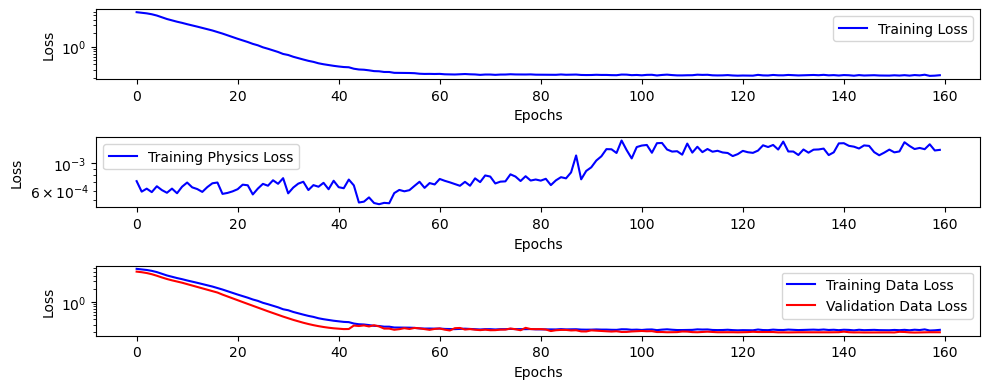

In [35]:
fig = arch.plot_losses()
fig.show()

In [36]:
predictions = arch.predict(df_test[features].values)
df_pred = pd.DataFrame(predictions, columns=target)
df_pred = df_test[features].join(df_pred)
df_pred.head()

,x,z,source_x0,source_z0,travel_time
0,0,0,1,0,1.749773
1,0,1,1,0,1.707502
2,0,2,1,0,2.356382
3,0,3,1,0,2.321765
4,0,4,1,0,2.128552


In [29]:
df_filtrado = df[(df['source_z0'] == 0) & (df['source_x0'] == 1)]
print(df_filtrado)

      x   z  travel_time  source_x0  source_z0
0     0   0     0.666667          1          0
1     0   1     0.872972          1          0
2     0   2     1.102162          1          0
3     0   3     1.270344          1          0
4     0   4     1.482011          1          0
..   ..  ..          ...        ...        ...
895  29  25     2.776042          1          0
896  29  26     2.799790          1          0
897  29  27     2.823745          1          0
898  29  28     2.847859          1          0
899  29  29     2.872091          1          0

[900 rows x 5 columns]


In [33]:
score(df_pred[target].values, df_test[target].values, ["travel_time"])

,travel_time
R²,-0.042905
MAPE,inf
MAE,0.412531
MSE,0.265503
RMSE,0.515270
